# Experiment 4: utility as the dataset grows

Age (`AGEP`, $d = 96$) is the QID and marital status (`MAR`, $k = 5$) the sensitive attribute. For each number of records $n$, 1000 releases $h \sim \mathrm{Mult}_n(\theta)$ are drawn and published raw, coarsened (ages in bins of $b$ years, $\gamma_b$) and randomized by $\mathrm{GRR}_k(p')$ on the marital status. The analyst has the benchmark prior and uses the optimal estimates of Propositions 6.2(a) and 7.2 on the raw and coarse releases, and the projected unbiased estimate from the proof of Proposition 7.4 on the randomized ones. Each curve is the mean utility gain (Definition 4.4) over the 1000 releases, with its 95% confidence interval.

This notebook produces **Figure 4** of the paper: **(a)** `figures/figure4a.pdf` (coarsening) and **(b)** `figures/figure4b.pdf` (GRR). The code of the experiment is in `utility_vs_n.py`, which uses the releases and estimates of `controls.py` (Experiment 3).

In [1]:
import numpy as np

import utility_vs_n as un
from build_pums2010 import build_dataset
from common import load_population

data_path = build_dataset()  # downloads and extracts the 2010 ACS PUMS on the first run

Population: 3,061,692 records with no N/A in AGEP, MAR


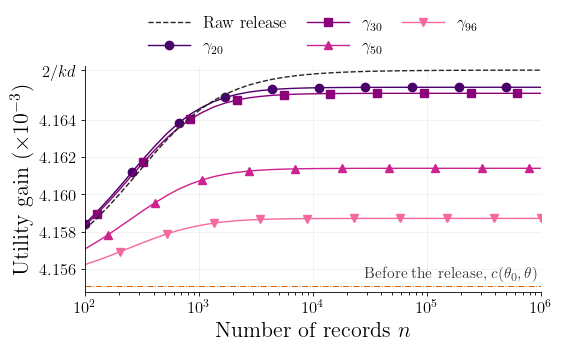

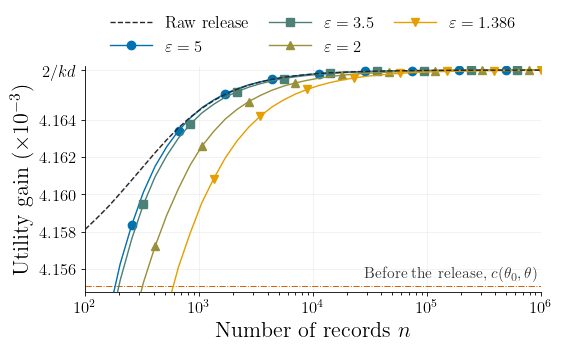

In [2]:
qids, sensitive = ["AGEP"], "MAR"  # QID: age; sensitive attribute: marital status
column = "AGEP"  # the QID column that is coarsened
sizes = np.unique(np.geomspace(100, 10**6, 40).astype(int))  # numbers of records n, 10^2 to 10^6
widths = [20, 30, 50, 96]  # coarsenings gamma_b: ages in bins of b years

theta = load_population(data_path, qids, sensitive)
k = theta.shape[1]  # sensitive values
# Levels of GRR on the sensitive attribute, from ln(k - 1) = 1.386, at which it keeps the true value
# with probability 1/2, to 5
epsilons = [np.log(k - 1), 2, 3.5, 5]
# For each n, the utility gain c of each release: its mean over the 1000 releases of n records and
# the half-width of its 95% confidence interval ("utility gain CI")
table = un.utility_table(theta, sizes, column, widths, epsilons)
un.plot(theta, table, widths, epsilons, ("figures/figure4a.pdf", "figures/figure4b.pdf"))

## Values of Figure 4

The mean utility gains in units of $10^{-3}$, a row per $n$ and a column per release (the half-widths of their confidence intervals are in `table["utility gain CI"]`).

In [3]:
table["utility gain"].unstack(sort=False) * 1e3

release,Raw,AGEP in bins of 20,AGEP in bins of 30,AGEP in bins of 50,AGEP in bins of 96,"GRR, ε = 1.38629","GRR, ε = 2","GRR, ε = 3.5","GRR, ε = 5"
n,,,,,,,,,
100,4.158118,4.158413,4.158319,4.157071,4.156229,4.128299,4.138302,4.144549,4.145700
126,4.158704,4.159041,4.158932,4.157435,4.156437,4.133538,4.142980,4.148873,4.149957
160,4.159344,4.159718,4.159587,4.157838,4.156669,4.137700,4.146997,4.152518,4.153472
203,4.160052,4.160444,4.160297,4.158273,4.156919,4.141613,4.150217,4.155381,4.156261
257,4.160772,4.161182,4.161014,4.158704,4.157164,4.145079,4.152834,4.157621,4.158367
325,4.161503,4.161906,4.161719,4.159141,4.157414,4.148353,4.155265,4.159458,4.160118
412,4.162240,4.162609,4.162400,4.159550,4.157650,4.151246,4.157215,4.160953,4.161510
522,4.162936,4.163259,4.163027,4.159935,4.157871,4.153807,4.158897,4.162086,4.162564
661,4.163572,4.163823,4.163571,4.160270,4.158062,4.156105,4.160313,4.163024,4.163416
